# 📉 | Elasticidade-Preço da Demanda

A elasticidade-preço da demanda é uma técnica utilizada pela Praso para quantificar a sensibilidade da demanda semanal dos produtos à variações no Índice de Preço ($IP$). A partir disso, conseguimos entender melhor como a escolha de preço influencia na demanda de um determinado produto.

Para isso, realizaremos a análise, que utiliza exclusivamente o conjunto de treino (`data/processed/painel/treino.csv`, semanas 2 a 9) e emprega a coluna `ip_observado`, garantindo que apenas preços reais de mercado sejam considerados e evitando relações artificiais ou vazamento temporal.

In [60]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

pd.set_option('display.float_format', lambda x: '%.4f' % x)
sns.set_theme(style="whitegrid")

### 1. Carregamento e filtragem dos dados de treino

Carregamos `painel/treino.csv` e filtramos apenas os registros em que o índice de preço foi efetivamente observado, houve venda e o produto não esteve 100% fora de estoque na semana.

In [61]:
df_treino = pd.read_csv('../data/processed/painel/treino.csv', parse_dates=['semana'])
df_treino['id_produto'] = df_treino['id_produto'].astype(str)

print(f"Total de linhas no painel de treino: {len(df_treino)}")
print(f"Linhas com cadastro de produto (tem_info_produto == 1): {(df_treino['tem_info_produto'] == 1).sum()}")
print(f"Linhas com IP real observado (ip_observado não nulo): {df_treino['ip_observado'].notna().sum()}")

Total de linhas no painel de treino: 2487
Linhas com cadastro de produto (tem_info_produto == 1): 621
Linhas com IP real observado (ip_observado não nulo): 467


In [62]:
# Filtro aplicado
df_ip = df_treino[
    df_treino['ip_observado'].notna() &
    (df_treino['pct_dias_sem_estoque'] < 1.0) &
    (df_treino['qtd_total'] > 0)
].copy()

print(f"Linhas válidas para estimativa de elasticidade: {len(df_ip)} ({df_ip['id_produto'].nunique()} produtos)")

Linhas válidas para estimativa de elasticidade: 456 (80 produtos)


### 2. Distribuição dos dados

Antes de qualquer cálculo, vale olhar o IP, a quantidade vendida e a relação entre os dois, para ver se uma reta que iremos gerar poderá dar uma boa descrição.

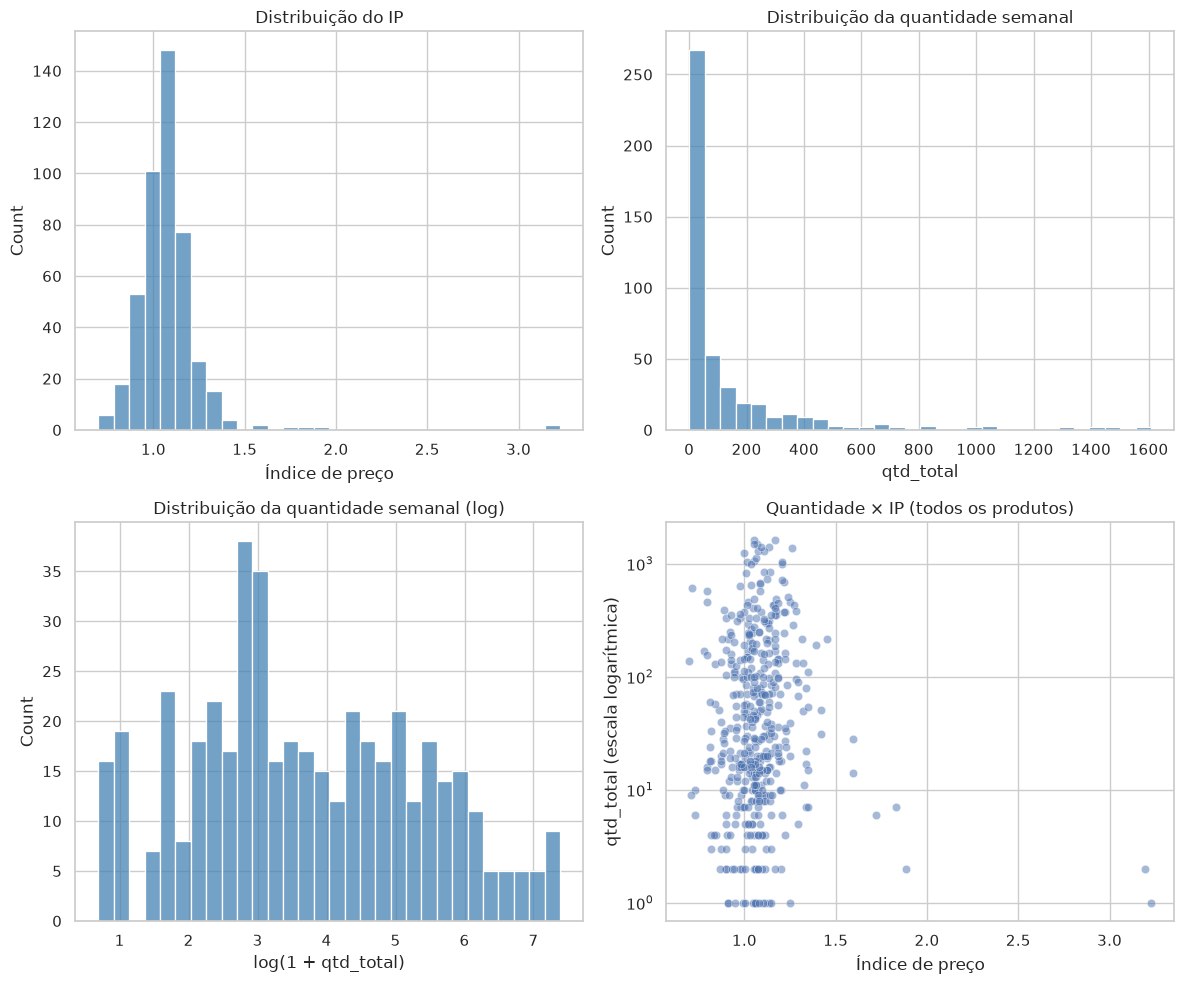

In [63]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
ax = axes.flatten()

sns.histplot(df_ip['ip_observado'], bins=30, ax=ax[0], color='steelblue')
ax[0].set_title('Distribuição do IP')
ax[0].set_xlabel('Índice de preço')

sns.histplot(df_ip['qtd_total'], bins=30, ax=ax[1], color='steelblue')
ax[1].set_title('Distribuição da quantidade semanal')
ax[1].set_xlabel('qtd_total')

sns.histplot(np.log1p(df_ip['qtd_total']), bins=30, ax=ax[2], color='steelblue')
ax[2].set_title('Distribuição da quantidade semanal (log)')
ax[2].set_xlabel('log(1 + qtd_total)')

sns.scatterplot(data=df_ip[df_ip['qtd_total'] > 0],
                x='ip_observado', y='qtd_total', alpha=0.5, ax=ax[3])
ax[3].set_yscale('log')
ax[3].set_title('Quantidade × IP (todos os produtos)')
ax[3].set_xlabel('Índice de preço')
ax[3].set_ylabel('qtd_total (escala logarítmica)')

plt.tight_layout()
plt.show()

Com isso, conseguimos perceber inicialmente que o IP fica concentrado numa mesma faixa, isto é, o preço da empresa varia pouco em relação ao mercado, com excessão de um ponto em específico acima de 3.0.

Já a respeito da quantidade, vemos que vai de 1 até cerca de 1600 unidades por semana, se concentrando mais na faixa de 1 à 100. Aplicando a transformação $\log{(1+p)}$, conseguimos reduzir um pouco mais a assimetria.

Por fim, correlacionando ambas as informações, podemos perceber que, para um mesmo valor de IP existem produtos vendendo desde 1 até a ordem de 1000 unidades. A diferença de volume entre os produtos domina o gráfico e esconde o efeito do preço, o que investigaremos melhor posteriormente.

### 3. Cálculo da elasticidade

Seguimos a definição do enunciado:

$$\varepsilon_D = \frac{\Delta Q}{\Delta IP} \cdot \frac{IP}{Q}$$

Ajustamos uma reta $Q = a + b \cdot IP$. A inclinação $b$ é o $\frac{\Delta Q}{\Delta IP}$, ou seja, quanto a quantidade muda quando o IP sobe uma unidade, e a elasticidade é $b$ multiplicado pela razão entre o IP médio e a quantidade média. 

O $R^2$ da reta, que vai de 0 a 1, mostra quanto da variação da quantidade a reta explica e é usado como medida de confiança. Valores de $|\varepsilon_D|$ acima de 1 indicam demanda elástica, e abaixo de 1, inelástica.

In [64]:
def calcular_elasticidade(df_sub, col_ip='ip_observado', col_q='qtd_total', min_obs=3):
    sub = df_sub[[col_ip, col_q]].dropna()
    n = len(sub)

    if n < min_obs or sub[col_ip].std() < 1e-6 or sub[col_q].std() < 1e-6:
        return pd.Series({'n_obs': n, 'elasticidade': np.nan, 'r2': np.nan})

    b, _, r, _, _ = stats.linregress(sub[col_ip], sub[col_q])
    elasticidade = b * sub[col_ip].mean() / sub[col_q].mean()
    return pd.Series({'n_obs': n, 'elasticidade': elasticidade, 'r2': r ** 2})

### 4. Estimativa por produto

Aplicamos a função a cada produto com IP observado no treino.

In [65]:
elast_produto = (
    df_ip.groupby('id_produto')
    .apply(calcular_elasticidade, include_groups=False)
    .reset_index()
)

validos = elast_produto['elasticidade'].notna()
print(f"Produtos com IP observado: {len(elast_produto)} | com estimativa válida: {validos.sum()}")
print(f"Observações por produto (mediana): {elast_produto['n_obs'].median():.0f}")
print(f"Produtos com R² >= 0.30: {(elast_produto['r2'] >= 0.30).sum()}")
elast_produto[validos][['n_obs', 'elasticidade', 'r2']].describe()

Produtos com IP observado: 80 | com estimativa válida: 68
Observações por produto (mediana): 6
Produtos com R² >= 0.30: 19


,n_obs,elasticidade,r2
count,68.0000,68.0000,68.0000
mean,6.3676,-1.2129,0.1985
std,1.7864,6.1860,0.2430
min,3.0000,-16.4906,0.0000
25%,5.0000,-4.2104,0.0303
50%,7.0000,-0.6659,0.0865
75%,8.0000,1.4694,0.3226
max,8.0000,17.6598,0.9146


### 5. Estimativa por curva e por categoria

Os produtos têm volumes muito diferentes, e juntar todos em uma única reta misturaria essa diferença com o efeito do preço. Por isso cada produto é comparado com ele mesmo de modo que a quantidade e o IP de cada semana são divididos pela média do próprio produto no treino, fazendo com que 1,0 signifique o valor típico daquele produto. Só entram produtos com pelo menos 3 semanas de IP observado e alguma variação significativa de preço (consideraremos $\gt 10^{-6}$).

In [66]:
prods = df_ip.groupby('id_produto')['ip_observado'].agg(['count', 'std'])
prods_validos = prods[(prods['count'] >= 3) & (prods['std'] > 1e-6)].index

df_norm = df_ip[df_ip['id_produto'].isin(prods_validos)].copy()
df_norm['qtd_norm'] = df_norm['qtd_total'] / df_norm.groupby('id_produto')['qtd_total'].transform('mean')
df_norm['ip_norm'] = df_norm['ip_observado'] / df_norm.groupby('id_produto')['ip_observado'].transform('mean')

def elasticidade_por(coluna):
    return (
        df_norm.groupby(coluna)
        .apply(lambda g: calcular_elasticidade(g, col_ip='ip_norm', col_q='qtd_norm'), include_groups=False)
        .reset_index()
    )

In [67]:
elast_curva = elasticidade_por('curva')
elast_curva

,curva,n_obs,elasticidade,r2
0,A,124.0000,-0.1410,0.0006
1,B,312.0000,-0.6713,0.0084


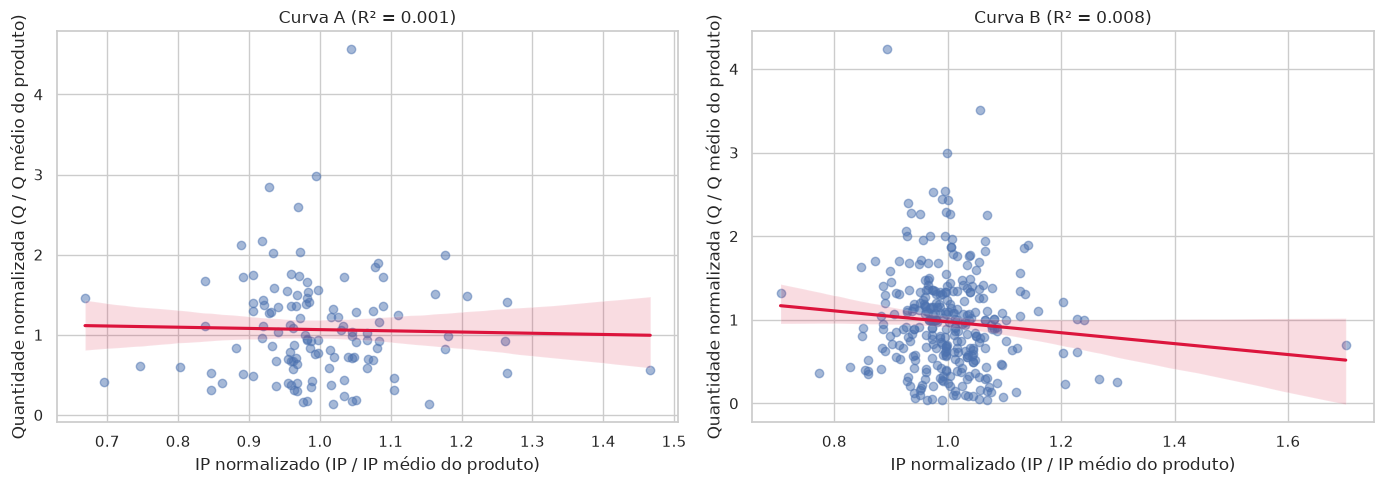

In [68]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for idx, c in enumerate(['A', 'B']):
    sub_p = df_norm[df_norm['curva'] == c]
    r2 = elast_curva.loc[elast_curva['curva'] == c, 'r2'].iloc[0]
    sns.regplot(
        data=sub_p, x='ip_norm', y='qtd_norm', ax=axes[idx],
        scatter_kws={'alpha': 0.5}, line_kws={'color': 'crimson'}
    )
    axes[idx].set_title(f'Curva {c} (R² = {r2:.3f})')
    axes[idx].set_xlabel('IP normalizado (IP / IP médio do produto)')
    axes[idx].set_ylabel('Quantidade normalizada (Q / Q médio do produto)')

plt.tight_layout()
plt.show()

As retas ajustadas são quase planas. O R² é 0,0006 na curva A e 0,0084 na curva B, ou seja, o IP explica menos de 1% da variação da quantidade em ambas. As elasticidades estimadas (A: −0,14 e B: −0,67) ficam abaixo de 1 em valor absoluto, o que indicaria demanda inelástica, mas com esse R², e com a inclinação da curva B apoiada em poucos pontos de IP alto, não há evidência de que o efeito seja diferente de zero.

In [69]:
elast_categoria = elasticidade_por('categoria')
elast_categoria

,categoria,n_obs,elasticidade,r2
0,Categoria 1,16.0000,-3.0729,0.1449
1,Categoria 10,31.0000,-0.9613,0.0064
2,Categoria 12,6.0000,7.0241,0.1311
3,Categoria 13,8.0000,4.6137,0.0067
4,Categoria 14,8.0000,-1.3492,0.0266
5,Categoria 15,13.0000,-0.5954,0.0075
6,Categoria 18,13.0000,-2.0393,0.0129
7,Categoria 19,13.0000,2.0656,0.0809
8,Categoria 2,14.0000,0.4728,0.0200
9,Categoria 20,36.0000,-1.1807,0.0214


In [70]:
elast_categoria.sort_values('n_obs', ascending=False).head(8)

,categoria,n_obs,elasticidade,r2
15,Categoria 28,43.0000,0.5543,0.0039
9,Categoria 20,36.0000,-1.1807,0.0214
19,Categoria 36,35.0000,-0.1952,0.0004
1,Categoria 10,31.0000,-0.9613,0.0064
30,Categoria 9,24.0000,-7.3168,0.3081
10,Categoria 21,23.0000,-0.1521,0.0004
0,Categoria 1,16.0000,-3.0729,0.1449
28,Categoria 7,16.0000,-0.8122,0.0458


### 6. Comparação entre os níveis

Por categoria, as maiores amostras são:

In [71]:
resumo_niveis = pd.DataFrame({
    'Nível': ['Produto', 'Categoria', 'Curva'],
    'Grupos com estimativa': [
        elast_produto['elasticidade'].notna().sum(),
        elast_categoria['elasticidade'].notna().sum(),
        elast_curva['elasticidade'].notna().sum(),
    ],
    'Observações por grupo (mediana)': [
        elast_produto['n_obs'].median(),
        elast_categoria['n_obs'].median(),
        elast_curva['n_obs'].median(),
    ],
    'R² médio': [
        elast_produto['r2'].mean(),
        elast_categoria['r2'].mean(),
        elast_curva['r2'].mean(),
    ],
}).set_index('Nível')
resumo_niveis

,Grupos com estimativa,Observações por grupo (mediana),R² médio
Nível,,,
Produto,68,6.0000,0.1985
Categoria,32,12.0000,0.1459
Curva,2,218.0000,0.0045


A partir disso, conseguimos estabelecer a seguinte comparação entre os grupos:

* **Produto:** 68 dos 80 produtos têm estimativa, com mediana de 6 semanas cada. As elasticidades vão de −16 a +18, e o R² médio de 0,20 é justamente o que se espera ao acaso com 6 pontos (cerca de $\frac{1}{n−1}$), então não indica relação real.
* **Categoria:** 32 grupos com mediana de 12 observações. As elasticidades mudam de sinal e de tamanho sem padrão (por exemplo, +0,55 na Categoria 28 e −7,3 na Categoria 9).
* **Curva:** só 2 grupos, mas com 124 e 312 observações. É o nível com menor R² (0,005), porém o mais estável.

Nenhum nível mostra uma relação forte, e agregar os dados não fortaleceu a correlação. Portanto, a princípio, o nível escolhido é a curva, por ter amostra suficiente em cada grupo de modo que esta é uma métrica menos granular, sabendo que o efeito do preço nesses dados é pequeno.

### 7. Exportação da elasticidade para o modelo de demanda

Exportamos a tabela do nível escolhido (curva), com a chave `curva` usada nos arquivos de `../data/processed/painel/`.

In [72]:
os.makedirs('../data/processed/elasticidade', exist_ok=True)

tabela_curva = elast_curva[['curva', 'elasticidade', 'r2']].rename(columns={
    'elasticidade': 'elasticidade_curva',
    'r2': 'r2_elasticidade_curva',
})

sem_cadastro = pd.DataFrame({'curva': ['Sem cadastro'], 'elasticidade_curva': [0.0], 'r2_elasticidade_curva': [0.0]})
tabela_curva = pd.concat([tabela_curva, sem_cadastro], ignore_index=True)
tabela_curva.to_csv('../data/processed/elasticidade/elasticidade_curva.csv', index=False)

tabela_curva

,curva,elasticidade_curva,r2_elasticidade_curva
0,A,-0.1410,0.0006
1,B,-0.6713,0.0084
2,Sem cadastro,0.0000,0.0000
